<a href="https://colab.research.google.com/github/profhamilton3/DataAnalytics/blob/main/kagglehub.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title Import Kaggle dataset
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jadeacevedo/sickle-cell-clinical-notes")

print("Path to dataset files:", path)

100%|██████████| 2.01M/2.01M [00:01<00:00, 1.59MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/jadeacevedo/sickle-cell-clinical-notes/versions/1


In [2]:
# @title the file I downloaded:
import os

# List the contents of the downloaded directory
if os.path.exists(path):
    files = os.listdir(path)
    print(f"Files in {path}:")
    for file in files:
        print(f"- {file}")
else:
    print(f"Path does not exist: {path}")

Files in /root/.cache/kagglehub/datasets/jadeacevedo/sickle-cell-clinical-notes/versions/1:
- sickle_cell_clinical_notes.csv


In [3]:
# @title data health
import pandas as pd
import os

# Construct the full path to the CSV file
csv_path = os.path.join(path, 'sickle_cell_clinical_notes.csv')

# Load the data
df = pd.read_csv(csv_path)

# Display basic information about the dataset to check health
print("--- Data Information ---")
df.info()

print("\n--- Missing Values Count ---")
display(df.isnull().sum().to_frame(name='Missing Values'))

print("\n--- Preview of the Data ---")
display(df.head())

--- Data Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 75016 entries, 0 to 75015
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         75016 non-null  object 
 1   visit_datetime     75016 non-null  object 
 2   facility_type      75016 non-null  object 
 3   pain_type          75016 non-null  object 
 4   pain_intensity     75016 non-null  int64  
 5   location           75016 non-null  object 
 6   admitted           75016 non-null  object 
 7   hemoglobin         75016 non-null  float64
 8   oxygen_saturation  75016 non-null  int64  
 9   clinical_note      75016 non-null  object 
 10  dob                75016 non-null  object 
 11  diagnosis_date     75016 non-null  object 
 12  gender             75016 non-null  object 
dtypes: float64(1), int64(2), object(10)
memory usage: 7.4+ MB

--- Missing Values Count ---


,Missing Values
patient_id,0
visit_datetime,0
facility_type,0
pain_type,0
pain_intensity,0
location,0
admitted,0
hemoglobin,0
oxygen_saturation,0
clinical_note,0



--- Preview of the Data ---


,patient_id,visit_datetime,facility_type,pain_type,pain_intensity,location,admitted,hemoglobin,oxygen_saturation,clinical_note,dob,diagnosis_date,gender
0,P00000,10/8/20,ER,Leg Pain,2,Bronx,Yes,6.6,98,45-year-old Female with a known history of sic...,10/27/16,7/16/20,Female
1,P00000,12/26/20,Clinic,Chest Pain,8,Queens,Yes,6.7,92,45-year-old Female with a known history of sic...,10/27/16,7/16/20,Female
2,P00000,2/21/21,Outpatient,Chest Pain,4,Staten Island,No,10.5,88,45-year-old Female with a known history of sic...,10/27/16,7/16/20,Female
3,P00000,8/7/21,Clinic,Leg Pain,8,Manhattan,No,9.2,95,45-year-old Female with a known history of sic...,10/27/16,7/16/20,Female
4,P00000,10/4/21,Urgent Care,Back Pain,6,Bronx,No,7.8,91,45-year-old Female with a known history of sic...,10/27/16,7/16/20,Female


# DATA Visuals

/tmp/ipykernel_25490/1989554217.py:59: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_time['visit_datetime'] = pd.to_datetime(df_time['visit_datetime'], errors='coerce')


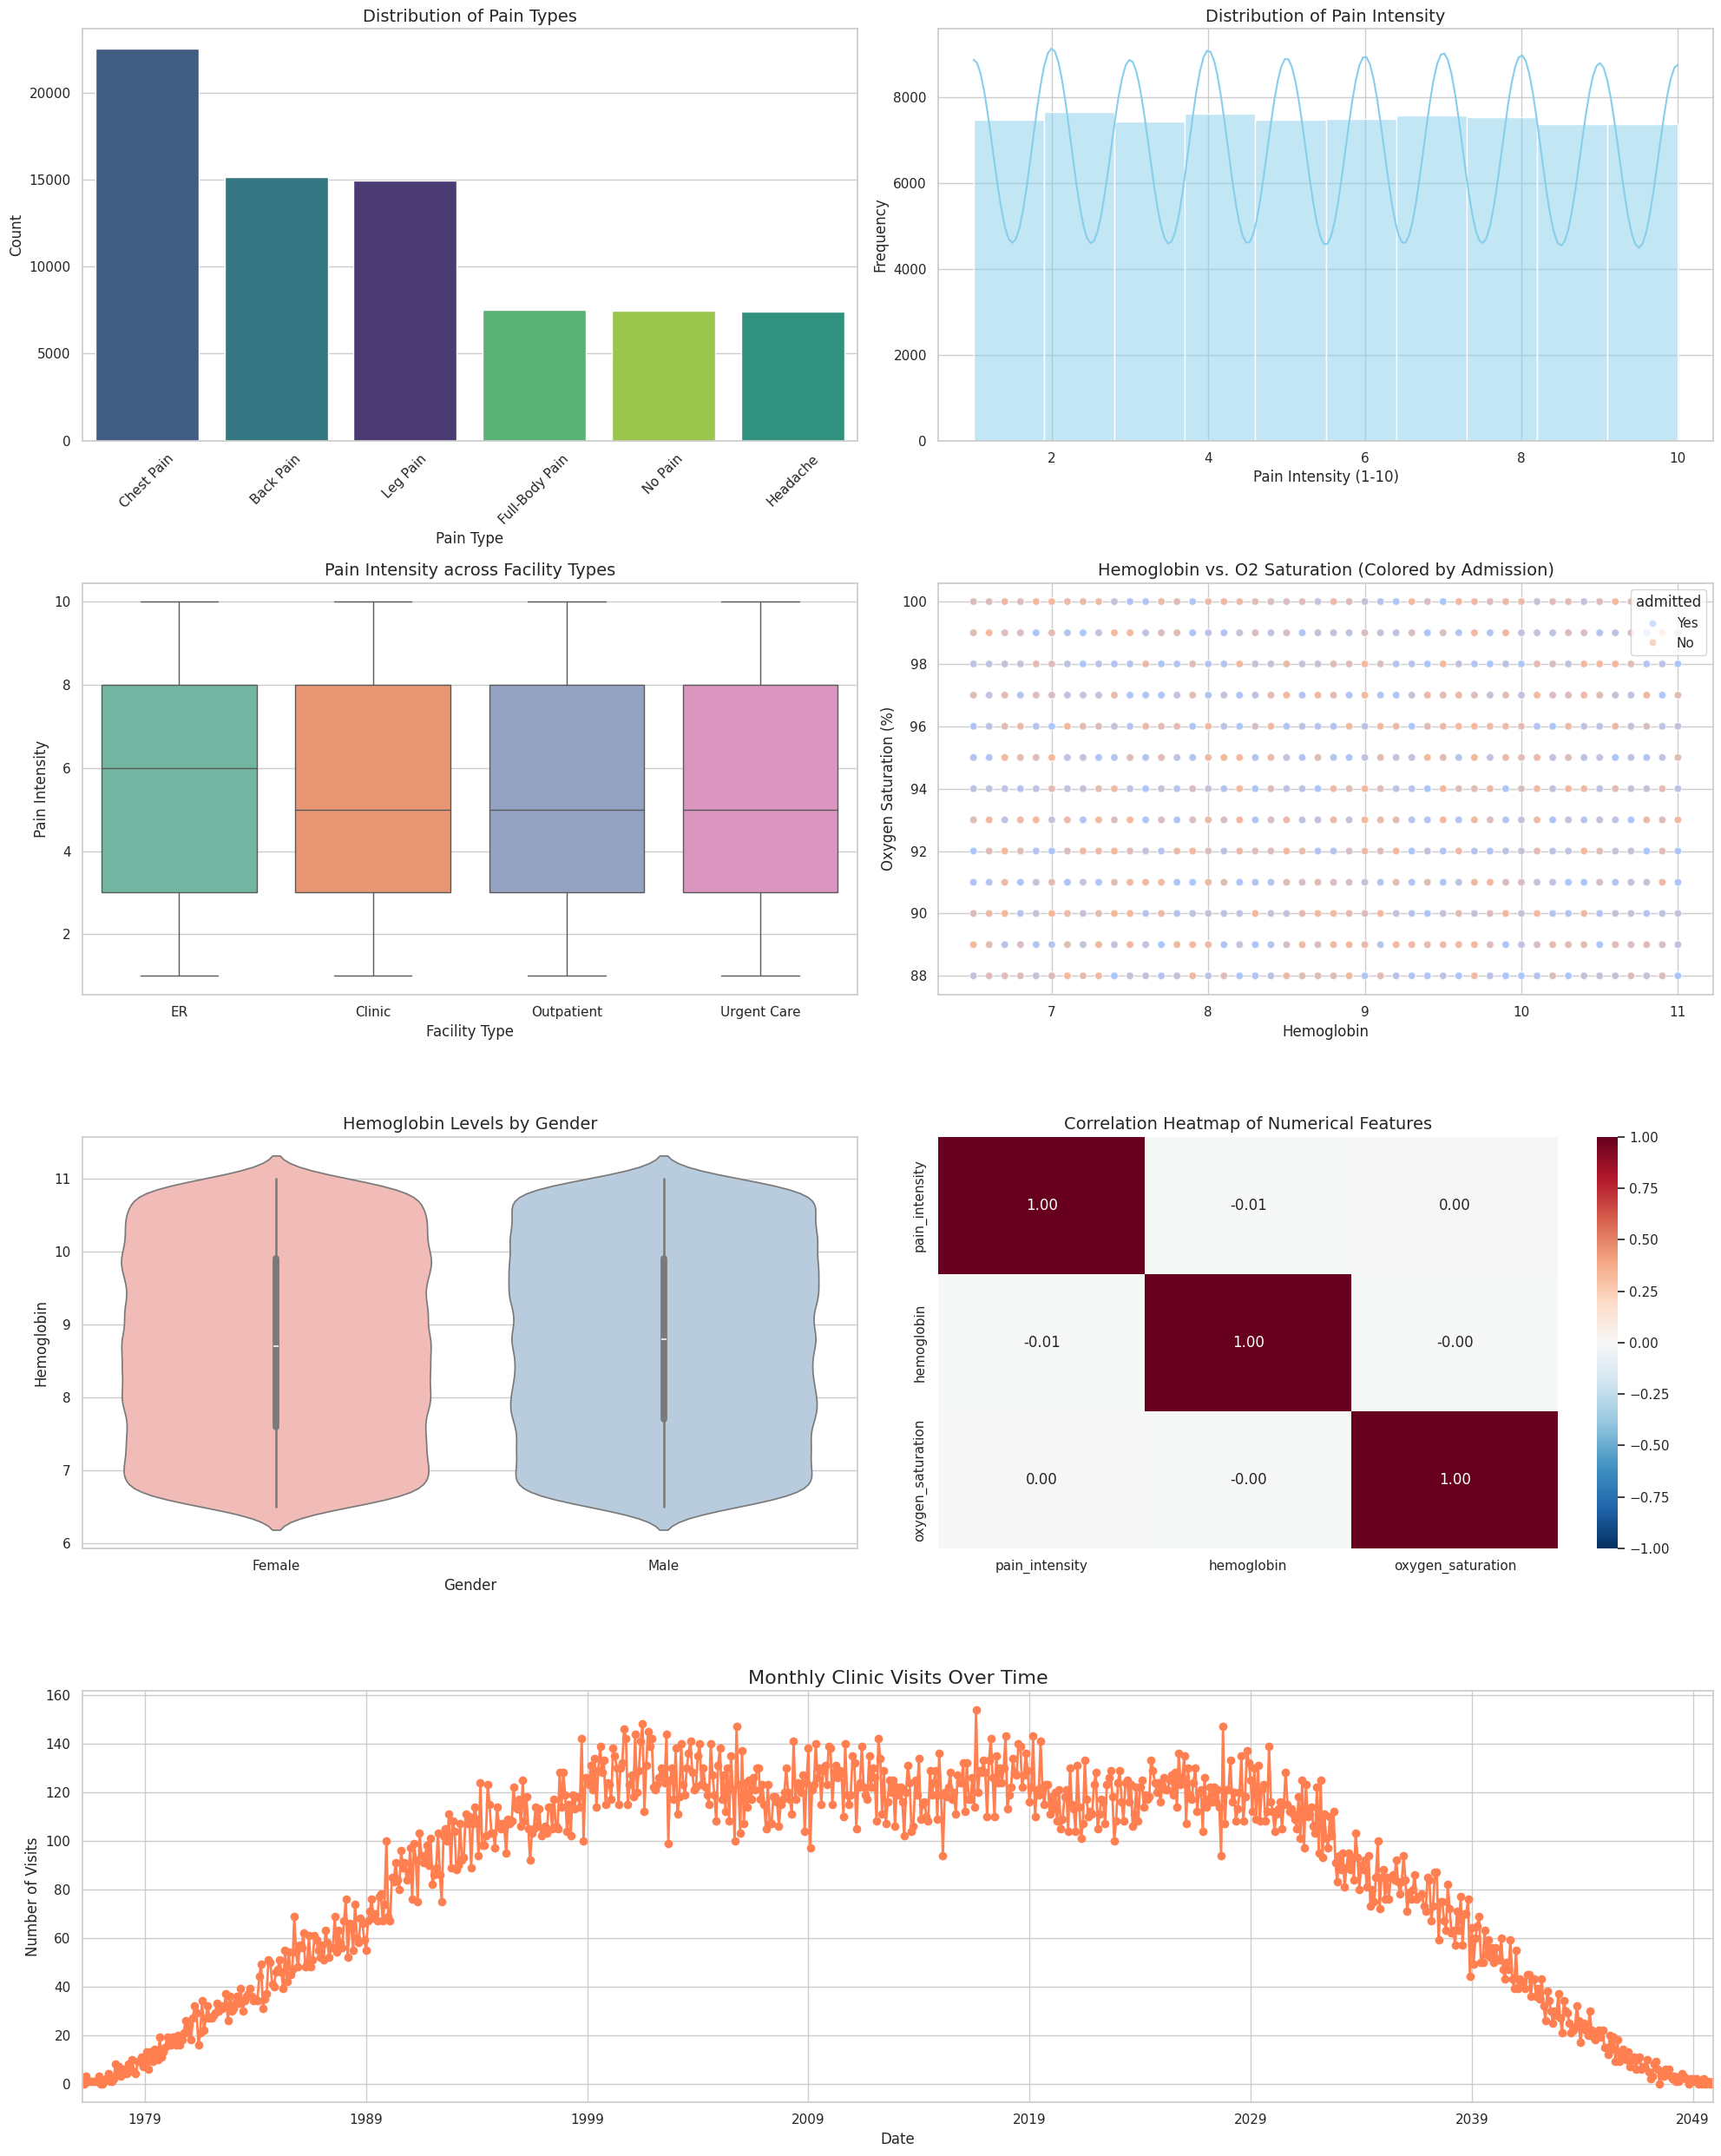

In [4]:
# @title 'python`
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set the aesthetic style of the plots
sns.set_theme(style="whitegrid")

# Create a figure with multiple subplots
fig = plt.figure(figsize=(20, 25))

# 1. Distribution of Categorical Variable: Pain Type (Countplot)
plt.subplot(4, 2, 1)
sns.countplot(data=df, x='pain_type', hue='pain_type', palette='viridis', order=df['pain_type'].value_counts().index, legend=False)
plt.title('Distribution of Pain Types', fontsize=14)
plt.xlabel('Pain Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# 2. Distribution of Numerical Variable: Pain Intensity (Histogram & KDE)
plt.subplot(4, 2, 2)
sns.histplot(df['pain_intensity'], bins=10, kde=True, color='skyblue')
plt.title('Distribution of Pain Intensity', fontsize=14)
plt.xlabel('Pain Intensity (1-10)')
plt.ylabel('Frequency')

# 3. Comparison using Boxplot: Pain Intensity by Facility Type
plt.subplot(4, 2, 3)
sns.boxplot(data=df, x='facility_type', y='pain_intensity', hue='facility_type', palette='Set2', legend=False)
plt.title('Pain Intensity across Facility Types', fontsize=14)
plt.xlabel('Facility Type')
plt.ylabel('Pain Intensity')

# 4. Relationship using Scatter Plot: Hemoglobin vs. Oxygen Saturation
plt.subplot(4, 2, 4)
sns.scatterplot(data=df, x='hemoglobin', y='oxygen_saturation', hue='admitted', alpha=0.6, palette='coolwarm')
plt.title('Hemoglobin vs. O2 Saturation (Colored by Admission)', fontsize=14)
plt.xlabel('Hemoglobin')
plt.ylabel('Oxygen Saturation (%)')

# 5. Density and Distribution using Violin Plot: Hemoglobin levels by Gender
plt.subplot(4, 2, 5)
sns.violinplot(data=df, x='gender', y='hemoglobin', hue='gender', palette='Pastel1', legend=False)
plt.title('Hemoglobin Levels by Gender', fontsize=14)
plt.xlabel('Gender')
plt.ylabel('Hemoglobin')

# 6. Correlation Heatmap for Numerical Features
plt.subplot(4, 2, 6)
# Select only numerical columns for correlation
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt=".2f")
plt.title('Correlation Heatmap of Numerical Features', fontsize=14)

# 7. Time Series Analysis: Number of Visits over Time (Monthly)
plt.subplot(4, 2, (7, 8)) # Span across two columns
# Create a copy to avoid modifying the original dataframe unnecessarily
df_time = df.copy()
df_time['visit_datetime'] = pd.to_datetime(df_time['visit_datetime'], format='mixed', errors='coerce')
df_time.set_index('visit_datetime', inplace=True)
monthly_visits = df_time.resample('ME').size() # ME is Month End frequency
monthly_visits.plot(kind='line', marker='o', color='coral', linewidth=2)
plt.title('Monthly Clinic Visits Over Time', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Number of Visits')
plt.grid(True)

# Adjust layout and display
plt.tight_layout()
plt.show()